# Exploração dos resultados

Gráficos do relatório, gerados a partir dos CSVs em `results/`. Cada figura também é salva em `results/figuras/`.

1. **Acurácia no dataset de treino por cliente**: FedMD adaptado, treino local, FedMD original e centralizado (`results/test_models`).
2. **Evolução de cada etapa do desenvolvimento incremental**: as etapas 1 a 9 da tabela do relatório. No eixo x estão os momentos de avaliação: `pub` (após o `public_init`), `priv` (após o `private_init`) e as rodadas federadas 1…R, cada uma avaliada ao fim da rodada (digest + revisit).
3. **Treino local (public + private init) em cada cenário** da configuração final.

Linha pontilhada: limite teórico (modelo centralizado, 0,898).

In [1]:
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

R = 'results'
FIG = os.path.join(R, 'figuras')
os.makedirs(FIG, exist_ok=True)

# Paleta categórica de referência (skill dataviz), slots 1-4 em ordem fixa: cada entidade mantém sempre a mesma cor.
C = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100']
TEXT, MUTED, GRID, SURFACE = '#0b0b0b', '#52514e', '#e4e3df', '#fcfcfb'
TETO = 0.898  # modelo centralizado, média das 4 arquiteturas (results/limite_teorico)

ALPHAS = ['iid', '1.0', '0.1']
ALPHA_LABEL = {'iid': 'IID', '1.0': 'α = 1.0', '0.1': 'α = 0.1'}
ALPHA_COLOR = dict(zip(ALPHAS, C))

plt.rcParams.update({
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE,
    'axes.edgecolor': GRID, 'axes.labelcolor': MUTED, 'axes.titlecolor': TEXT, 'axes.titlesize': 11,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'axes.grid.axis': 'y',
    'grid.color': GRID, 'grid.linewidth': 0.8, 'xtick.color': MUTED, 'ytick.color': MUTED,
    'legend.frameon': False, 'axes.axisbelow': True, 'font.size': 10, 'lines.linewidth': 2,
})


def load(path):
    """CSV de métricas com alpha como texto e coluna seed (as primeiras execuções não tinham)."""
    t = pd.read_csv(path)
    t['alpha'] = t['alpha'].astype(str)
    if 'seed' not in t:
        t['seed'] = 42
    return t


def save(fig, name):
    fig.savefig(os.path.join(FIG, f'{name}.png'), dpi=200, bbox_inches='tight')

## 1. Acurácia por cliente: as 4 configurações

5% de dados públicos, média ± desvio padrão entre as seeds disponíveis. Usa os resultados de `results/test_models`. Enquanto o experimento não termina, aparecem só as seeds concluídas. O centralizado não depende de α, então as mesmas 4 arquiteturas aparecem nos três painéis.

- **FedMD adaptado**: média das rodadas 26-30.
- **Local (public + private init)**: os mesmos clientes logo após o `private_init`, sem colaboração.
- **FedMD original**: média das rodadas 16-20.
- **Centralizado**: cada arquitetura treinada com todo o conjunto de treino.

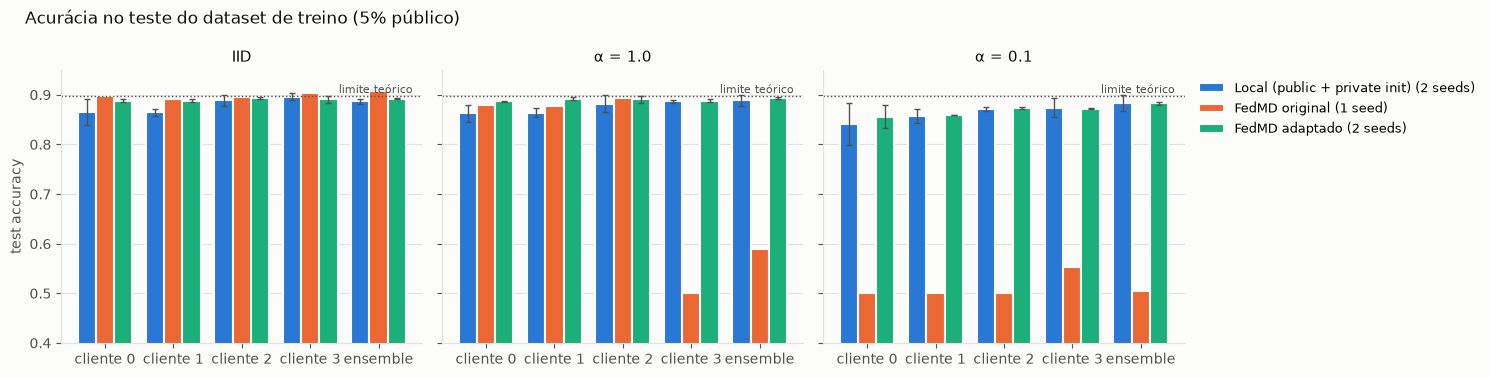

In [2]:
METODOS = ['Local (public + private init)', 'FedMD original', 'FedMD adaptado', 'Centralizado']
METODO_COLOR = dict(zip(METODOS, C))
MODELOS = ['cliente 0', 'cliente 1', 'cliente 2', 'cliente 3', 'ensemble']


def resultados_4_configuracoes():
    """Uma linha por método, alpha, seed e modelo, com acurácia no teste original e no PH2."""
    D = f'{R}/test_models'
    rows = []
    fontes = [('FedMD adaptado', 'adaptado', 'federated', (26, 30)),
              ('Local (public + private init)', 'adaptado', 'private_init', None),
              ('FedMD original', 'original', 'federated', (16, 20))]
    for metodo, prefix, stage, rounds in fontes:
        for seed in (42, 1, 2):
            base = f'{D}/{prefix}_seed{seed}'
            if not os.path.exists(f'{base}_extra_test_metrics.csv'):
                continue  # execução ainda não concluída
            t, e, x = (load(f'{base}_{f}.csv') for f in ('test_metrics', 'ensemble_metrics', 'extra_test_metrics'))
            sel = lambda df: df[(df.stage == stage) & (df['round'].between(*rounds) if rounds else True)]
            t, e, x = sel(t), sel(e), sel(x)
            for alpha in ALPHAS:
                for modelo in MODELOS:
                    xs = x[(x.alpha == alpha) & (x.model == modelo)]
                    if modelo == 'ensemble':
                        test = e[e.alpha == alpha].ensemble_accuracy.mean()
                    else:
                        test = t[(t.alpha == alpha) & (t.client_id == int(modelo[-1]))].test_accuracy.mean()
                    rows.append({'método': metodo, 'alpha': alpha, 'seed': seed, 'modelo': modelo, 'test_accuracy': test,
                                 'ph2_accuracy': xs.accuracy.mean(), 'ph2_balanced_accuracy': xs.balanced_accuracy.mean()})
    if os.path.exists(f'{D}/centralizado.csv'):
        c = pd.read_csv(f'{D}/centralizado.csv')
        for _, r in c.iterrows():
            modelo = 'ensemble' if r.model == 'ensemble' else r.model.replace('arquitetura', 'cliente')
            for alpha in ALPHAS:  # o centralizado não depende de alpha: repetido em cada painel
                rows.append({'método': 'Centralizado', 'alpha': alpha, 'seed': r.seed, 'modelo': modelo,
                             'test_accuracy': r.test_accuracy, 'ph2_accuracy': r.ph2_accuracy,
                             'ph2_balanced_accuracy': r.ph2_balanced_accuracy})
    return pd.DataFrame(rows)


def barras_por_cliente(df, metrica, titulo, ylim, referencia=None, nome=None):
    fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
    metodos = [m for m in METODOS if m in set(df['método'])]
    largura = 0.8 / len(metodos)
    xs = np.arange(len(MODELOS))
    for ax, alpha in zip(axes, ALPHAS):
        for i, metodo in enumerate(metodos):
            g = df[(df['método'] == metodo) & (df.alpha == alpha)].groupby('modelo')[metrica]
            m, s, n = g.mean().reindex(MODELOS), g.std().reindex(MODELOS), g.count().max()
            ax.bar(xs + (i - (len(metodos) - 1) / 2) * largura, m, largura, yerr=s if n > 1 else None,
                   color=METODO_COLOR[metodo], edgecolor=SURFACE, linewidth=1.5,
                   error_kw={'ecolor': MUTED, 'elinewidth': 1, 'capsize': 2}, label=f'{metodo} ({n} seed{"s" if n > 1 else ""})')
        if referencia is not None:
            ax.axhline(referencia[0], color=MUTED, ls=':', lw=1)
            ax.text(len(MODELOS) - 0.5, referencia[0], referencia[1], color=MUTED, fontsize=8, ha='right', va='bottom')
        ax.set_xticks(xs, MODELOS)
        ax.set_ylim(*ylim)
        ax.set_title(ALPHA_LABEL[alpha])
    axes[0].set_ylabel(metrica.replace('_', ' '))
    axes[-1].legend(loc='upper left', bbox_to_anchor=(1.01, 1), fontsize=9)
    fig.suptitle(titulo, color=TEXT, x=0.02, ha='left')
    fig.tight_layout()
    if nome:
        save(fig, nome)
    plt.show()


quatro = resultados_4_configuracoes()
barras_por_cliente(quatro, 'test_accuracy', 'Acurácia no teste do dataset de treino (5% público)', (0.4, 0.95),
                   referencia=(TETO, 'limite teórico'), nome='1_teste_por_cliente')

### Avaliação externa: PH2

No PH2, 80% das imagens são benignas, então prever "benigno" para tudo já dá 0,80 de acurácia (linha pontilhada). A acurácia balanceada, que é a média do recall de cada classe, dá 0,5 para esse modelo trivial e é a métrica mais justa para esse dataset.

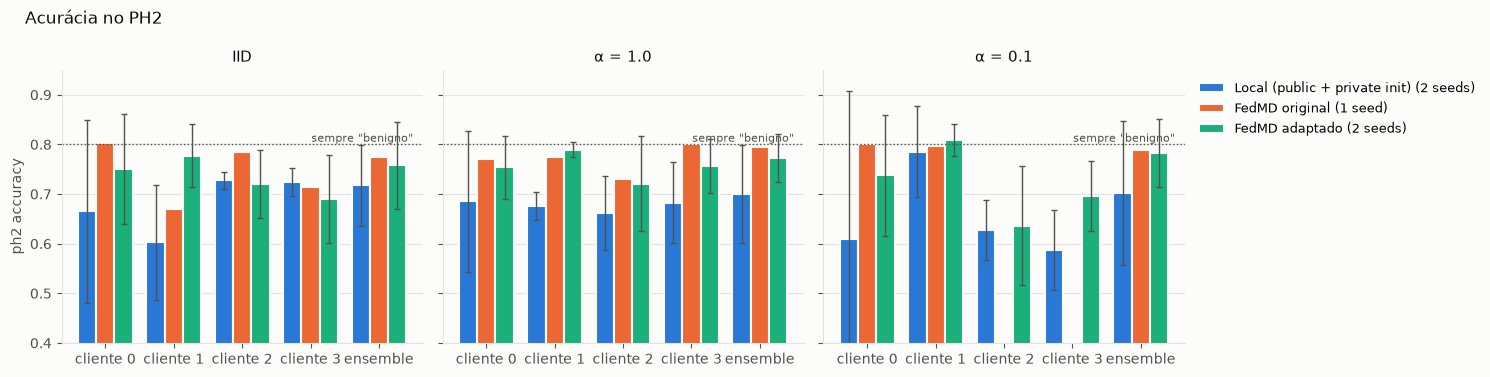

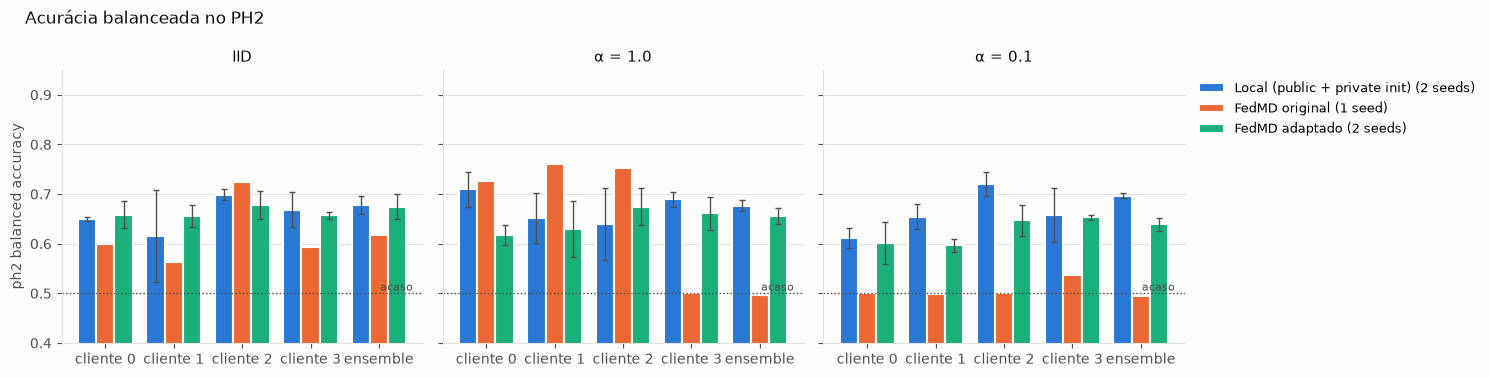

In [3]:
barras_por_cliente(quatro, 'ph2_accuracy', 'Acurácia no PH2', (0.4, 0.95), referencia=(0.80, 'sempre "benigno"'),
                   nome='1_ph2_acuracia_por_cliente')
barras_por_cliente(quatro, 'ph2_balanced_accuracy', 'Acurácia balanceada no PH2', (0.4, 0.95),
                   referencia=(0.5, 'acaso'), nome='1_ph2_balanceada_por_cliente')

## 2. Etapas do desenvolvimento incremental

Média de acurácia dos 4 clientes no teste. Cada painel é uma fração pública, e cada linha é uma divisão dos dados privados. As etapas 1 a 5 e 7 a 9 usam frações de 10%, 40% e 80%, com seed 42, a menos que outra seed esteja indicada. A linha tracejada separa a inicialização das rodadas federadas.

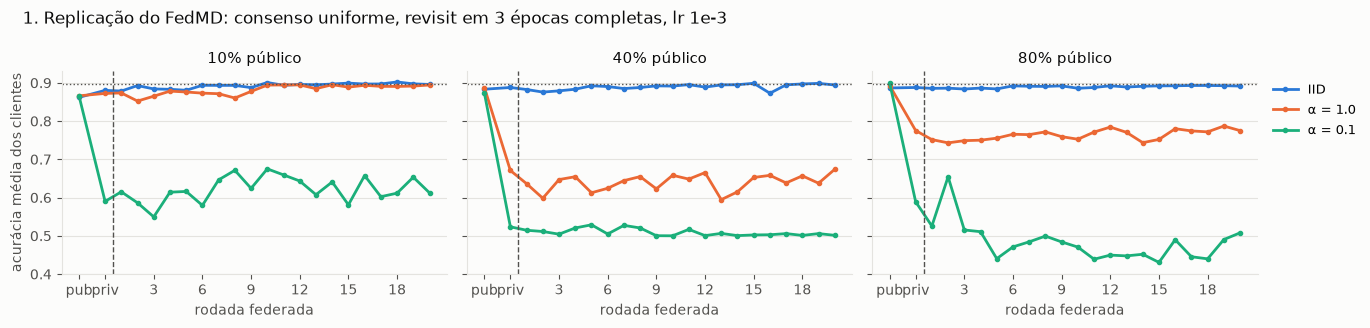

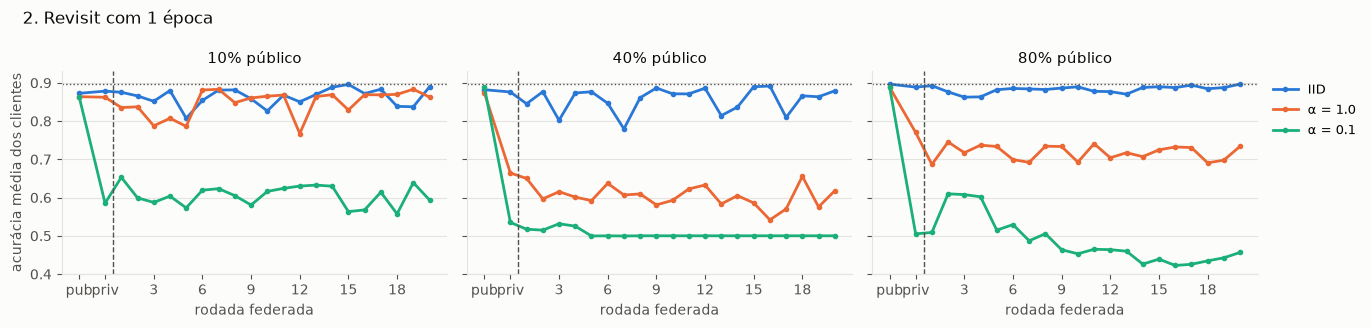

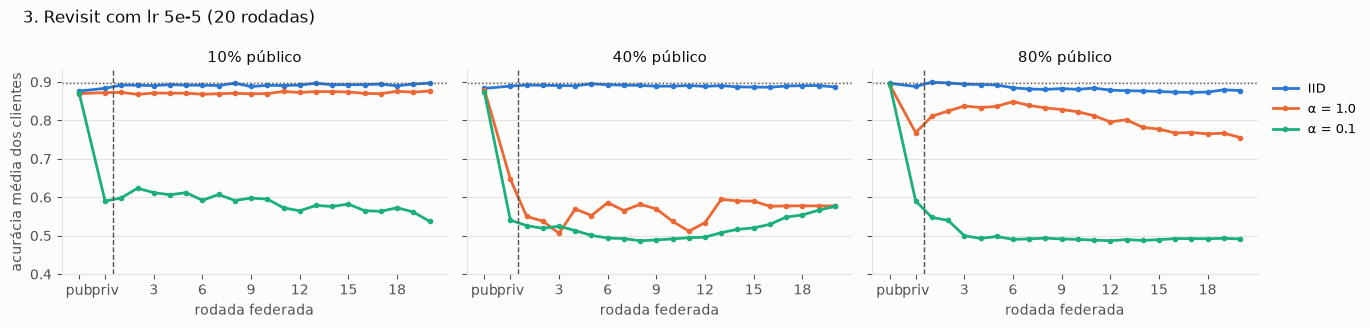

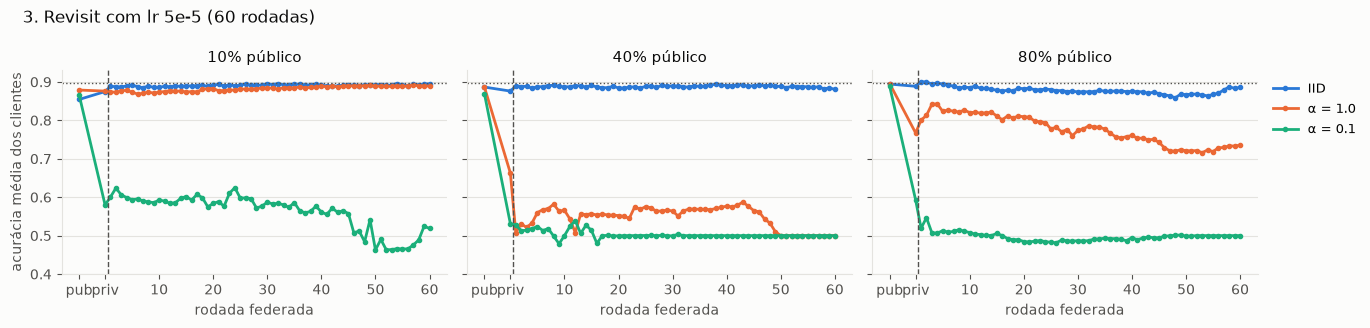

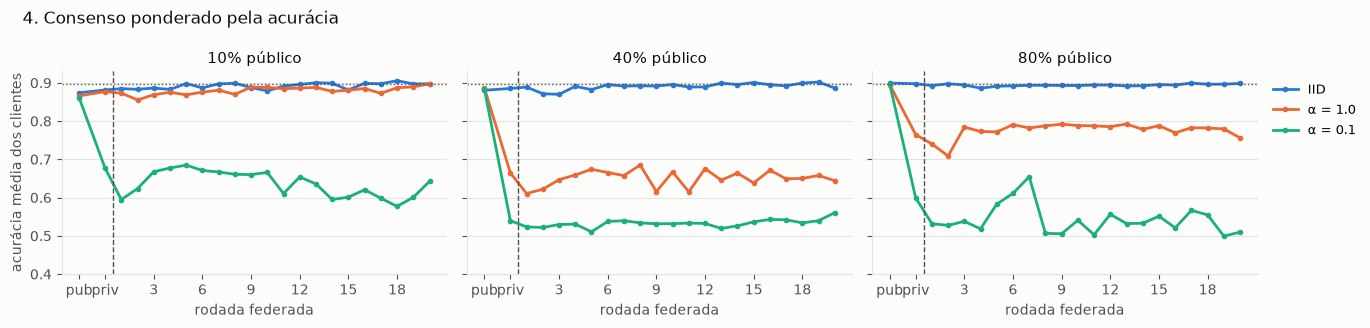

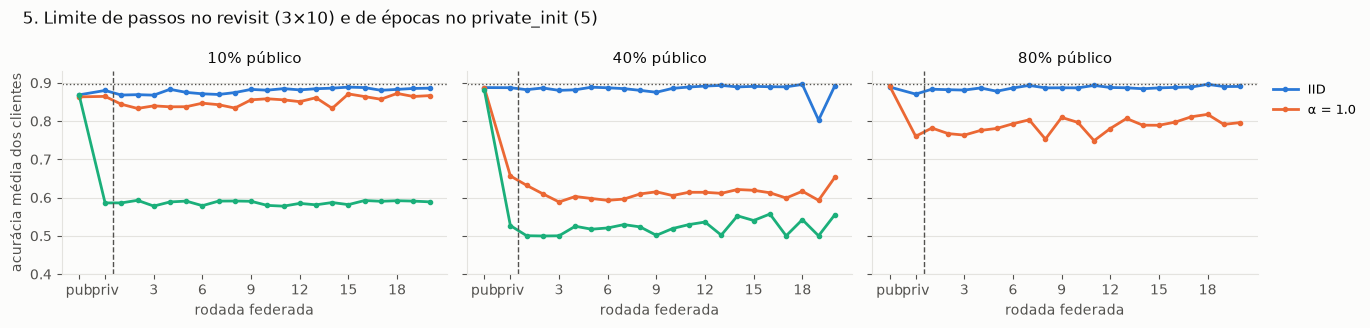

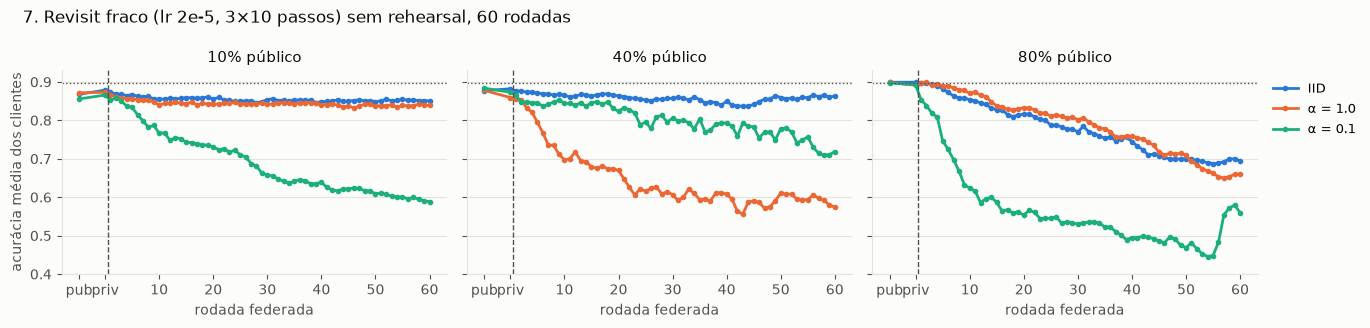

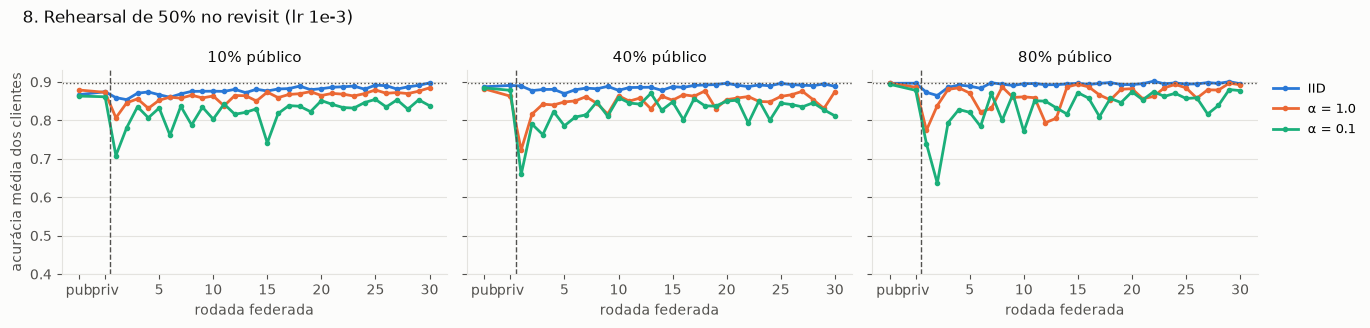

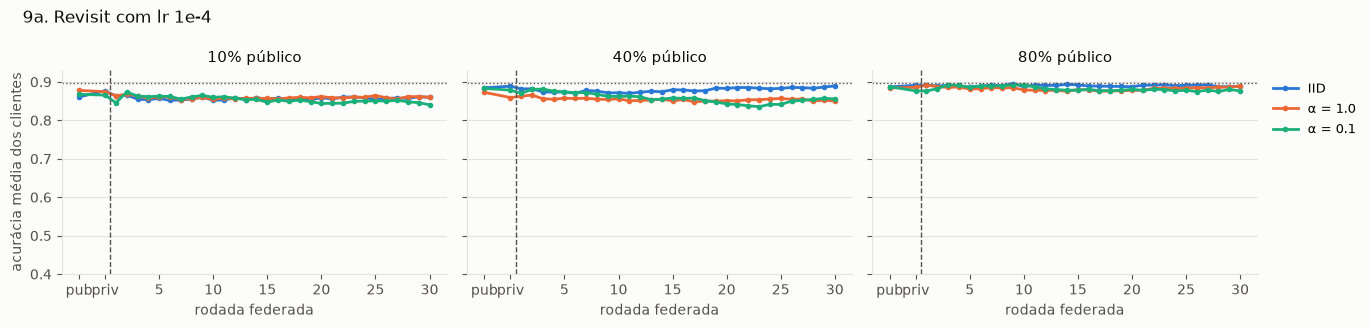

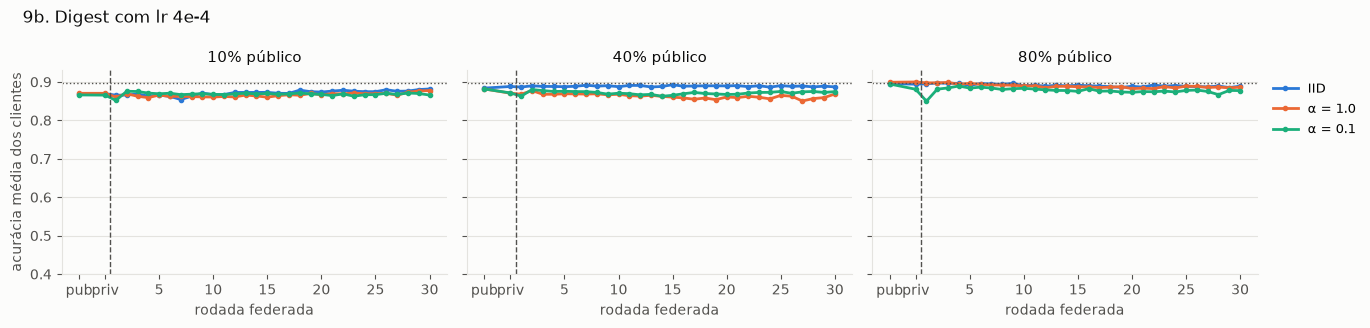

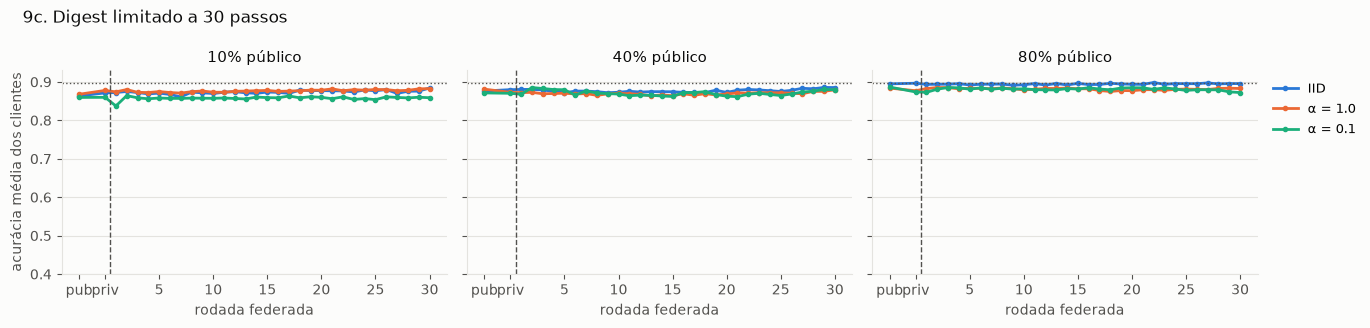

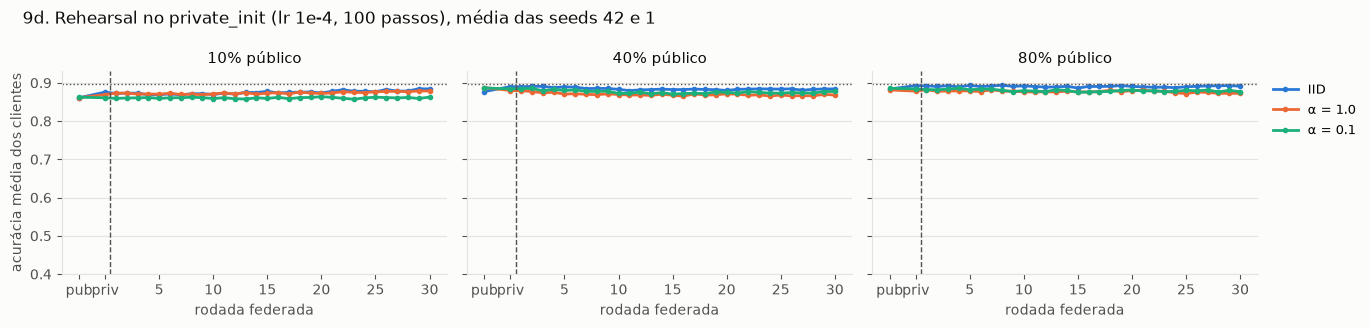

In [4]:
def curva(t):
    """Média dos clientes por fração, alpha e momento de avaliação (-1 = pub, 0 = priv, k = rodada k)."""
    t = t.copy()
    t['ponto'] = np.select([t.stage == 'public_init', t.stage == 'private_init'], [-1, 0], t['round']).astype(float)
    return t.groupby(['public_fraction', 'alpha', 'ponto']).test_accuracy.mean().reset_index()


def plot_etapa(nome, titulo, paths):
    c = curva(pd.concat([load(p) for p in paths]))
    fracs = sorted(c.public_fraction.unique())
    fig, axes = plt.subplots(1, len(fracs), figsize=(4.6 * len(fracs), 3.3), sharey=True, squeeze=False)
    ultimo = int(c.ponto.max())
    gap = max(1.5, 0.08 * ultimo)  # distância visual entre pub e priv, proporcional ao número de rodadas
    c.loc[c.ponto == -1, 'ponto'] = -gap
    passo = max(1, ultimo // 6)
    ticks = list(range(passo, ultimo + 1, passo))
    for ax, f in zip(axes[0], fracs):
        for alpha in ALPHAS:
            s = c[(c.public_fraction == f) & (c.alpha == alpha)]
            if not s.empty:
                ax.plot(s.ponto, s.test_accuracy, color=ALPHA_COLOR[alpha], marker='o', ms=3, label=ALPHA_LABEL[alpha])
        ax.axvline(0.5, color=MUTED, ls='--', lw=1)
        ax.axhline(TETO, color=MUTED, ls=':', lw=1)
        ax.set_xticks([-gap, 0] + ticks, ['pub', 'priv'] + [str(k) for k in ticks])
        ax.set_ylim(0.4, 0.93)
        ax.set_xlabel('rodada federada')
        ax.set_title(f'{f * 100:g}% público')
    axes[0][0].set_ylabel('acurácia média dos clientes')
    axes[0][-1].legend(loc='upper left', bbox_to_anchor=(1.01, 1), fontsize=9)
    fig.suptitle(titulo, color=TEXT, x=0.02, ha='left')
    fig.tight_layout()
    save(fig, f'2_etapa_{nome}')
    plt.show()


ETAPAS = [
    ('01', '1. Replicação do FedMD: consenso uniforme, revisit em 3 épocas completas, lr 1e-3',
     ['01_replicacao_fedmd/test_metrics_3_private_epoch.csv']),
    ('02', '2. Revisit com 1 época', ['02_revisit_1_epoca/test_metrics_1_private_epoch.csv']),
    ('03a', '3. Revisit com lr 5e-5 (20 rodadas)', ['03_revisit_lr_5e-5/test_metrics_3_private_epoch_lr5e-5.csv']),
    ('03b', '3. Revisit com lr 5e-5 (60 rodadas)', ['03_revisit_lr_5e-5/test_metrics_3_private_epoch_lr5e-5_60_rounds.csv']),
    ('04', '4. Consenso ponderado pela acurácia', ['04_consenso_ponderado/test_metrics_3_private_epoch_weighted.csv']),
    ('05', '5. Limite de passos no revisit (3×10) e de épocas no private_init (5)',
     ['05_limite_passos_revisit_private_init/test_metrics_3_private_epoch_weighted_10_steps_init5.csv']),
    ('07', '7. Revisit fraco (lr 2e-5, 3×10 passos) sem rehearsal, 60 rodadas', ['07_revisit_fraco_sem_rehearsal/cen2_test_metrics.csv']),
    ('08', '8. Rehearsal de 50% no revisit (lr 1e-3)', ['08_rehearsal_no_revisit/cen3_test_metrics.csv']),
    ('09a', '9a. Revisit com lr 1e-4', ['09a_revisit_lr_1e-4/lr1e-4_test_metrics.csv']),
    ('09b', '9b. Digest com lr 4e-4', ['09b_digest_lr_4e-4/lr4e-4_test_metrics.csv']),
    ('09c', '9c. Digest limitado a 30 passos', ['09c_digest_30_passos/steps30_test_metrics.csv']),
    ('09d', '9d. Rehearsal no private_init (lr 1e-4, 100 passos), média das seeds 42 e 1',
     ['09d_rehearsal_private_init/B_init1e-4_seed42_test_metrics.csv', '09d_rehearsal_private_init/C_init1e-4_seed1_test_metrics.csv']),
]
for nome, titulo, arquivos in ETAPAS:
    plot_etapa(nome, titulo, [f'{R}/{a}' for a in arquivos])

### Etapa 6: varredura do `private_init` (sem rodadas federadas)

Variação da acurácia de cada cliente entre o `public_init` e o `private_init`. As barras mostram a média dos 36 clientes (9 configurações × 4), e os pontos, o pior cliente. A linha tracejada é o critério de quebra (−0,05).

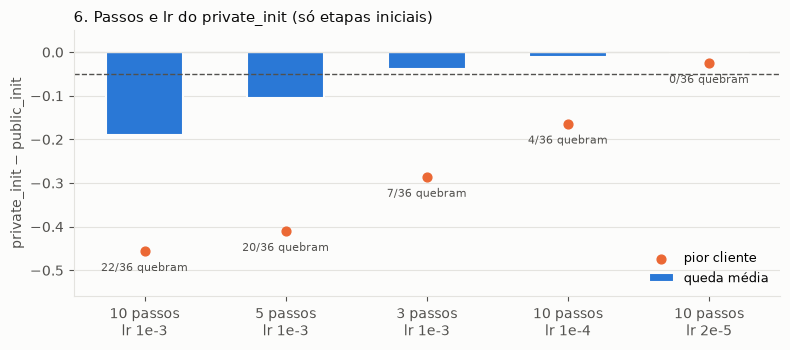

In [5]:
VARREDURA = [('cen1_init10', '10 passos\nlr 1e-3'), ('cen1_init5', '5 passos\nlr 1e-3'), ('cen1_init3', '3 passos\nlr 1e-3'),
             ('cen1_init10_lr1e-4', '10 passos\nlr 1e-4'), ('cen1_init10_lr2e-5', '10 passos\nlr 2e-5')]
k = ['public_fraction', 'alpha', 'client_id']
linhas = []
for prefixo, rotulo in VARREDURA:
    t = load(f'{R}/06_private_init_10_passos_lr_2e-5/{prefixo}_test_metrics.csv')
    d = t[t.stage == 'private_init'].set_index(k).test_accuracy - t[t.stage == 'public_init'].set_index(k).test_accuracy
    linhas.append({'teste': rotulo, 'média': d.mean(), 'pior': d.min(), 'quebram': int((d < -0.05).sum())})
v = pd.DataFrame(linhas)

fig, ax = plt.subplots(figsize=(8, 3.6))
xs = np.arange(len(v))
ax.bar(xs, v['média'], 0.55, color=C[0], edgecolor=SURFACE, linewidth=1.5, label='queda média')
ax.scatter(xs, v['pior'], color=C[1], s=40, zorder=3, label='pior cliente')
for x, (_, r) in zip(xs, v.iterrows()):
    ax.text(x, r['pior'] - 0.025, f"{r['quebram']}/36 quebram", ha='center', va='top', fontsize=8, color=MUTED)
ax.axhline(-0.05, color=MUTED, ls='--', lw=1)
ax.axhline(0, color=GRID, lw=1)
ax.set_xticks(xs, v['teste'])
ax.set_ylim(-0.56, 0.05)
ax.set_ylabel('private_init − public_init')
ax.legend(loc='lower right', fontsize=9)
ax.set_title('6. Passos e lr do private_init (só etapas iniciais)', loc='left')
fig.tight_layout()
save(fig, '2_etapa_06')
plt.show()

## 3. Treino local (public + private init) em cada cenário

Configuração final, com média ± desvio padrão de 3 seeds. As barras mostram a acurácia logo após o `public_init` e após o `public_init` + `private_init`, que é a linha de base do estudo.

Fontes:
- 1% e 5%: `ensemble_e_leave_one_out` (`all_*`)
- 20%: `fracoes_publicas_5_e_20` (seeds 42 e 1) e `experimento_final` (seed 2)

O `public_init` e o `private_init` são os mesmos nessas execuções. Elas só diferem no digest, que não afeta estas etapas.

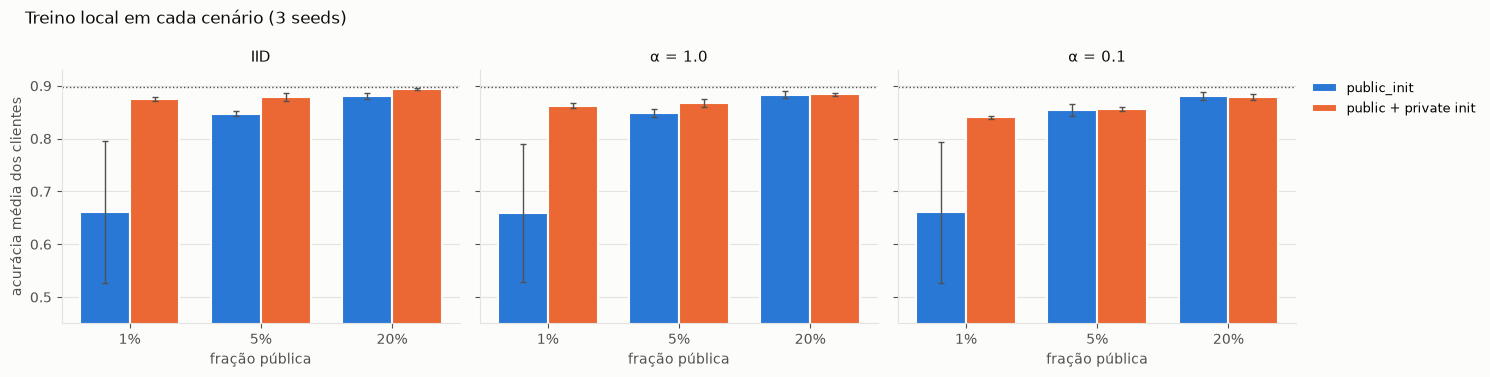

etapa         public + private init  public_init
fração alpha                                    
0.01   0.1                    0.840        0.660
       1.0                    0.862        0.659
       iid                    0.875        0.662
0.05   0.1                    0.856        0.854
       1.0                    0.868        0.848
       iid                    0.879        0.847
0.20   0.1                    0.879        0.881
       1.0                    0.884        0.883
       iid                    0.894        0.880

In [6]:
FONTES_LOCAL = {
    0.01: [f'ensemble_e_leave_one_out/all_P01_seed{s}' for s in (42, 1, 2)],
    0.05: [f'ensemble_e_leave_one_out/all_P05_seed{s}' for s in (42, 1, 2)],
    0.2: ['fracoes_publicas_5_e_20/F2_seed42', 'fracoes_publicas_5_e_20/F2_seed1', 'experimento_final/P20_seed2'],
}
linhas = []
for frac, bases in FONTES_LOCAL.items():
    for base in bases:
        t = load(f'{R}/{base}_test_metrics.csv')
        t = t[t.public_fraction == frac]
        for alpha in ALPHAS:
            for stage, rotulo in (('public_init', 'public_init'), ('private_init', 'public + private init')):
                linhas.append({'fração': frac, 'alpha': alpha, 'seed': t.seed.iloc[0], 'etapa': rotulo,
                               'acc': t[(t.alpha == alpha) & (t.stage == stage)].test_accuracy.mean()})
local = pd.DataFrame(linhas)

ETAPAS_LOCAL = ['public_init', 'public + private init']
FRACS = sorted(FONTES_LOCAL)
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
xs = np.arange(len(FRACS))
for ax, alpha in zip(axes, ALPHAS):
    for i, etapa in enumerate(ETAPAS_LOCAL):
        g = local[(local.alpha == alpha) & (local.etapa == etapa)].groupby('fração').acc
        ax.bar(xs + (i - 0.5) * 0.38, g.mean().reindex(FRACS), 0.38, yerr=g.std().reindex(FRACS), color=C[i],
               edgecolor=SURFACE, linewidth=1.5, error_kw={'ecolor': MUTED, 'elinewidth': 1, 'capsize': 2}, label=etapa)
    ax.axhline(TETO, color=MUTED, ls=':', lw=1)
    ax.set_xticks(xs, [f'{f * 100:g}%' for f in FRACS])
    ax.set_xlabel('fração pública')
    ax.set_ylim(0.45, 0.93)
    ax.set_title(ALPHA_LABEL[alpha])
axes[0].set_ylabel('acurácia média dos clientes')
axes[-1].legend(loc='upper left', bbox_to_anchor=(1.01, 1), fontsize=9)
fig.suptitle('Treino local em cada cenário (3 seeds)', color=TEXT, x=0.02, ha='left')
fig.tight_layout()
save(fig, '3_local_por_cenario')
plt.show()

local.pivot_table(index=['fração', 'alpha'], columns='etapa', values='acc', aggfunc='mean').round(3)